In [1]:
# Install packages
%pip install -q --no-cache-dir \
    "netket==3.23.0" \
    "flax==0.12.10" \
    "plum-dispatch==2.9.0" \
    "beartype==0.22.9"

In [2]:
# Connect to GPU
import os
#os.environ["JAX_PLATFORM_NAME"] = "cpu"
os.environ["JAX_PLATFORM_NAME"] = "gpu"

# Access Google drive (if running this in Google colab)
#from google.colab import drive
#drive.mount('/content/drive', force_remount=True)

#from google.colab import files

In [3]:
# Import packages
import jax
import jax.numpy as jnp
import flax
import optax
import netket as nk
import netket.experimental as nkx
import numpy as np
import scipy
import matplotlib.pyplot as plt
import json

# Check that JAX sees the GPU
print("JAX version:", jax.__version__)
print("Flax version:", flax.__version__)
print("NetKet version:", nk.__version__)
print("Devices:", jax.devices())

JAX version: 0.11.1
Flax version: 0.12.10
NetKet version: 3.23.0
Devices: [CudaDevice(id=0)]


In [4]:
# Define system

# 1D chain of size L
L = 12

# Define system graph: 1D periodic chain of length L
g = nk.graph.Hypercube(length=L, n_dim=1, pbc=True)   # impose periodic boundary doncitions
symmetries = g.translation_group()

# Hilbert space of spins on the graph
hi = nk.hilbert.Spin(s=1/2, N=g.n_nodes)


# Define XYZ Hamiltonian parameters
J_x = 1 # XX coupling
J_y = J_x  # YY coupling
J_z = 0.25 # ZZ coupling
h_x = 0.25 # transverse magnetic field

# Define XYZ Hamiltonian
from netket.operator.spin import sigmax, sigmaz, sigmay
ha = sum([-1*J_y*sigmay(hi,i)@sigmay(hi,(i+1) % L) for i in range(L)])
ha += sum([-1*J_x*sigmax(hi,i)@sigmax(hi,(i+1) % L) for i in range(L)])
ha += sum([-1*J_z*sigmaz(hi,i)@sigmaz(hi,(i+1) % L) for i in range(L)])
ha += sum([-1*h_x*sigmax(hi,i) for i in range(L)])


# Define observables: XX correlation function and X magnetization
corr_x = sigmax(hi, 0)@sigmax(hi, 1)
mag_x = sigmax(hi, 0)

# Because the system is periodic, we also consider spatially averaging over all sites
corr_x_avg = 1/L*sum([sigmax(hi,i)@sigmax(hi,(i+1)%L) for i in range(L)])
mag_x_avg = 1/L*sum([sigmax(hi,i) for i in range(L)])

In [5]:
# Compute energy eigenvalues
from scipy.sparse.linalg import eigsh
sp_ha = ha.to_sparse()
eig_vals, eig_vecs = eigsh(sp_ha, k=40, which="SA")
print("eigenvalues with scipy sparse:", eig_vals)

# Compute spectral gap
E_gs = eig_vals[0]
spectral_gap = eig_vals[1] - eig_vals[0]
print("\n spectral gap: ", spectral_gap)

# Compute exact ground state observables
sp_corr_x = corr_x.to_sparse()
sp_mag_x = mag_x.to_sparse()

corr_x_gs = np.real(np.conjugate(np.transpose(eig_vecs[:,0])) @ (sp_corr_x @ eig_vecs[:,0]))
mag_x_gs = np.real(np.conjugate(np.transpose(eig_vecs[:,0])) @ (sp_mag_x @ eig_vecs[:,0]))
conn_corr_x_gs = corr_x_gs - mag_x_gs**2

print("\n Exact XX correlation function: " + str(corr_x_gs))
print("Exact X magnetization: " + str(mag_x_gs))
print("Exact XX connected correlation function: " + str(conn_corr_x_gs))

eigenvalues with scipy sparse: [-16.5197542  -15.10292804 -14.2589591  -13.84264075 -14.2589591
 -13.09362316 -13.09362316 -12.7351554  -12.66497983 -12.62393789
 -12.84170782 -12.84170782 -12.4439812  -12.40876313 -12.40541563
 -12.4439812  -12.06404677 -12.40876313 -12.40541563 -11.97103697
 -11.9610373  -11.92923244 -12.08033921 -12.08033921 -11.97103697
 -11.92923244 -11.50432248 -11.83461126 -11.83530226 -11.83530226
 -11.83461126 -11.61231206 -11.61231206 -11.50432248 -11.1203345
 -11.20566355 -10.99446787 -11.20566355 -10.99446787 -10.93624674]

 spectral gap:  1.4168261667388435

 Exact XX correlation function: 0.8693396851163987
Exact X magnetization: 0.8702333126579022
Exact XX connected correlation function: 0.11203366665685266


# **Estimate Ground State**

In [6]:
# Define NQS as a symmetric RBM
ma = nk.models.RBMSymm(alpha=2, symmetries=symmetries, param_dtype=complex)

# Define sampler that uses Metropolis local sampling
sa = nk.sampler.MetropolisHamiltonian(hi, ha, n_chains=32)

# Define variational state
vs = nk.vqs.MCState(sa, ma, n_samples=2048, n_discard_per_chain=64)
vs.init_parameters(init_fun=jax.nn.initializers.normal(stddev=0.01), seed=42)

In [7]:
# Define optimizer as SPRING with momentum
op = nk.optimizer.Sgd(learning_rate=1e-3)
#op = nk.optimizer.Sgd(learning_rate=optax.linear_schedule(1e-3, 5e-4, 1500))

# Define Variational monte carlo driver
gs = nk.driver.VMC_SR(ha, op, variational_state=vs, diag_shift=1e-3, momentum=0.95)

Automatic SR implementation choice: QGT (n_parameters=27, n_samples=2048)
Automatic SR on_the_fly choice: False


In [8]:
#Define function to log parameters during optimization

def log_parameters(step, log_data, driver):
  # Callback function to store current NQS parameters in pars
  vs = driver.state   # get the VariationalState from the driver
  pars = flax.core.copy(vs.parameters, {})

  # Store inside runtime log dictionary
  log_data["Parameters"] = pars

  return True

In [9]:
# Run the optimization for n_iter iterations to estimate the ground state
log = nk.logging.RuntimeLog()
n_iter = 1500
gs.run(n_iter=n_iter, out=log, obs={"corr_x": corr_x, "mag_x": mag_x,
                                    "corr_x_avg": corr_x_avg, "mag_x_avg": mag_x_avg}, callback=log_parameters)

  0%|          | 0/1500 [00:00<?, ?it/s]

(RuntimeLog():
  keys = ['Energy', 'acceptance', 'wallclock', 'info', 'Parameters', 'corr_x', 'corr_x_avg', 'mag_x', 'mag_x_avg'],)

In [10]:
# Logs the parameters over the iterations
pars_log = log["Parameters"]

# Store the parameters and state of the energy minimization
opt_pars = flax.core.copy(vs.parameters, {})

# **Evaluate Observables**

In [26]:
# Define functions used in evaluating dynamical averaging correction

def commutator(A, B):
  # Compute commutator of two matrices
  comm = A @ B - B @ A
  return comm




def shift_pauli_strings(op, shift):
  # Shift a Pauli strings operator to the right by shift
  op = op.collect()
  N = op.hilbert.size
  shift %= N
  shifted_strings = [s[-shift:] + s[:-shift] if shift != 0 else s for s in op.operators]
  shifted_op = nk.operator.PauliStrings(op.hilbert, shifted_strings, op.weights, dtype=op.dtype,)
  return shifted_op




def compute_spatially_averaged_observables(O, L):
  # Compute O using spatial averaging

  # List of O anchored at site j
  Os = [O.copy()]
  for j in range(1, L):
    tmp = shift_pauli_strings(O.copy(), j)
    Os.append(tmp)

  # Average over Os
  O_avg = Os[0].copy()
  for j in range(1, L):
    O_avg += Os[j].copy()
  O_avg = 1/L*O_avg
  O_avg = O_avg.collect()

  return O_avg




def compute_C1_C3(O, hi, L, J_x, J_y, J_z, h_x):
  # Compute ha_comm, C1, C3 for an observable O

  # Compute support of observable and the support needed for its nested commutators
  site = 0    # O is assumed to have its leftmost non-trivial support on site 0
  O_support = sum(p != "I" for p in O.operators[0]) # Support of O
  ha_comm_support_range = (np.arange(site-4, site+4 + O_support) % L)

  # Compute Hamiltonian used for the nested commutators
  ha_comm = sum([-1*J_y*sigmay(hi,i)@sigmay(hi,(i+1) % L) for i in ha_comm_support_range])
  ha_comm += sum([-1*J_x*sigmax(hi,i)@sigmax(hi,(i+1) % L) for i in ha_comm_support_range])
  ha_comm += sum([-1*J_z*sigmaz(hi,i)@sigmaz(hi,(i+1) % L) for i in ha_comm_support_range])
  ha_comm += sum([-1*h_x*sigmax(hi,i) for i in ha_comm_support_range])
  ha_comm = ha_comm.to_pauli_strings()

  # Compute nested commutators
  C1 = commutator(ha_comm, O)
  C2 = commutator(ha_comm, C1)
  C3 = commutator(ha_comm, C2)

  # Compute spatial average of C1 and C3 for use in variational Monte Carlo
  C1_avg = compute_spatially_averaged_observables(C1, L)
  C3_avg = compute_spatially_averaged_observables(C3, L)

  return C1_avg, C3_avg





def dyn_avg_corrected_exp_val(O, vs, n_samples, hi, L, J_x, J_y, J_z, h_x):
  # Compute observable with dynamical averaging correction

  # Convert observable to Pauli string object
  if isinstance(O, nk.operator._pauli_strings.PauliStringsBase) == False:
    O = O.to_pauli_strings()

  # Compute spatially-averaged nested commutators
  C1_avg, C3_avg = compute_C1_C3(O, hi, L, J_x, J_y, J_z, h_x)

  # Sample from vs
  vs.n_samples = n_samples
  vs.sample()

  # Compute O using spatial averaging
  O_avg = compute_spatially_averaged_observables(O, L)
  O_stats = vs.expect(O_avg)
  O_mean = jnp.real(O_stats.mean)
  O_stdev = O_stats.error_of_mean

  # Compute local observables
  ha_loc  = vs.local_estimators(ha)
  C1_avg_loc = vs.local_estimators(C1_avg)
  C3_avg_loc = vs.local_estimators(C3_avg)
  E_ref = jnp.real(np.mean(ha_loc))

  # Compute estimators for C2 and C4
  C2_loc = 2*jnp.real(jnp.conj(ha_loc - E_ref)*C1_avg_loc)
  C2_stats = nk.stats.statistics(C2_loc)
  C4_loc = 2*jnp.real(jnp.conj(ha_loc - E_ref)*C3_avg_loc)
  C4_stats = nk.stats.statistics(C4_loc)

  # Compute dynamical averaging correction
  lam = 1e-12
  dyn_avg_correction = C2_stats.mean**2/(C4_stats.mean + lam)
  dyn_avg_correction_stdev = dyn_avg_correction*np.sqrt(4*C2_stats.error_of_mean**2/C2_stats.mean**2 + C4_stats.error_of_mean**2/(C4_stats.mean+lam)**2)

  # Compute corrected observable
  O_corrected = O_mean - dyn_avg_correction
  O_corrected_stdev = np.sqrt(O_stdev**2 + dyn_avg_correction_stdev**2)

  return O_mean, O_stdev, O_corrected, O_corrected_stdev





def dyn_avg_corrected_exp_val_XYZ(ha, corr_x, mag_x, vs, n_samples, hi, L, J_x, J_y, J_z, h_x):
  # Compute observables relevant to XYZ Model (energy, correlation function,
  # and magnetization) using the correction term from approximate dynamical
  # averaging in the Heisenberg picture

  # Convert operations to Pauli strings
  corr_x = corr_x.to_pauli_strings()
  mag_x = mag_x.to_pauli_strings()

  # Compute spatially-averaged nested commutators
  C1_corr_x_avg, C3_corr_x_avg = compute_C1_C3(corr_x, hi, L, J_x, J_y, J_z, h_x)
  C1_mag_x_avg, C3_mag_x_avg = compute_C1_C3(mag_x, hi, L, J_x, J_y, J_z, h_x)

  # Sample from vs
  vs.n_samples = n_samples
  vs.sample()

  # Compute energy
  E_stats = vs.expect(ha)
  E_mean = jnp.real(E_stats.mean)
  E_stdev = E_stats.error_of_mean

  # Compute corr_x using spatial averaging
  corr_x_avg = compute_spatially_averaged_observables(corr_x, L)
  corr_x_avg_stats = vs.expect(corr_x_avg)
  corr_x_avg_mean = jnp.real(corr_x_avg_stats.mean)
  corr_x_avg_stdev = corr_x_avg_stats.error_of_mean

  # Compute mag_x using spatial averaging
  mag_x_avg = compute_spatially_averaged_observables(mag_x, L)
  mag_x_avg_stats = vs.expect(mag_x_avg)
  mag_x_avg_mean = jnp.real(mag_x_avg_stats.mean)
  mag_x_avg_stdev = mag_x_avg_stats.error_of_mean

  # Compute local observables
  ha_loc  = vs.local_estimators(ha)
  E_ref = jnp.real(np.mean(ha_loc))
  C1_corr_x_avg_loc = vs.local_estimators(C1_corr_x_avg)
  C3_corr_x_avg_loc = vs.local_estimators(C3_corr_x_avg)
  C1_mag_x_avg_loc = vs.local_estimators(C1_mag_x_avg)
  C3_mag_x_avg_loc = vs.local_estimators(C3_mag_x_avg)

  # Compute estimators for C2 and C4
  C2_corr_x_loc = 2*jnp.real(jnp.conj(ha_loc - E_ref)*C1_corr_x_avg_loc)
  C2_corr_x_stats = nk.stats.statistics(C2_corr_x_loc)
  C4_corr_x_loc = 2*jnp.real(jnp.conj(ha_loc - E_ref)*C3_corr_x_avg_loc)
  C4_corr_x_stats = nk.stats.statistics(C4_corr_x_loc)

  C2_mag_x_loc = 2*jnp.real(jnp.conj(ha_loc - E_ref)*C1_mag_x_avg_loc)
  C2_mag_x_stats = nk.stats.statistics(C2_mag_x_loc)
  C4_mag_x_loc = 2*jnp.real(jnp.conj(ha_loc - E_ref)*C3_mag_x_avg_loc)
  C4_mag_x_stats = nk.stats.statistics(C4_mag_x_loc)

  # Compute dynamical averaging corrections
  lam = 1e-12
  corr_x_dyn_avg_correction = C2_corr_x_stats.mean**2/(C4_corr_x_stats.mean + lam)
  tmp1 = 4*C2_corr_x_stats.error_of_mean**2/C2_corr_x_stats.mean**2
  tmp2 = C4_corr_x_stats.error_of_mean**2/(C4_corr_x_stats.mean+lam)**2
  corr_x_dyn_avg_correction_stdev = corr_x_dyn_avg_correction*np.sqrt(tmp1 + tmp2)

  mag_x_dyn_avg_correction = C2_mag_x_stats.mean**2/(C4_mag_x_stats.mean + lam)
  tmp1 = 4*C2_mag_x_stats.error_of_mean**2/C2_mag_x_stats.mean**2
  tmp2 = C4_mag_x_stats.error_of_mean**2/(C4_mag_x_stats.mean+lam)**2
  mag_x_dyn_avg_correction_stdev = mag_x_dyn_avg_correction*np.sqrt(tmp1 + tmp2)

  # Compute corrected observables
  corr_x_corrected = corr_x_avg_mean - corr_x_dyn_avg_correction
  corr_x_corrected_stdev = np.sqrt(corr_x_avg_stdev**2 + corr_x_dyn_avg_correction_stdev**2)
  mag_x_corrected = mag_x_avg_mean - mag_x_dyn_avg_correction
  mag_x_corrected_stdev = np.sqrt(mag_x_avg_stdev**2 + mag_x_dyn_avg_correction_stdev**2)

  # Package results
  E_data = (E_mean, E_stdev)
  corr_x_data = (corr_x_avg_mean, corr_x_avg_stdev)
  corr_x_corrected_data = (corr_x_corrected, corr_x_corrected_stdev)
  mag_x_data = (mag_x_avg_mean, mag_x_avg_stdev)
  mag_x_corrected_data = (mag_x_corrected, mag_x_corrected_stdev)

  return E_data, corr_x_data, corr_x_corrected_data, mag_x_data, mag_x_corrected_data

In [17]:
# Compute observables (standard and dynamcially averaged) throughout optimization

# Step size in between collected data points and corresponding iterations
step_size = 100
max_iter = n_iter
iterations = np.arange(0,max_iter,step_size)


# Define arrays that will store observables
Energy_vs = np.zeros(len(iterations))
Energy_vs_stdev = np.zeros(len(iterations))

corr_x_vs = np.zeros(len(iterations))
corr_x_vs_stdev = np.zeros(len(iterations))
corr_x_vs_DA = np.zeros(len(iterations))
corr_x_vs_DA_stdev = np.zeros(len(iterations))

mag_x_vs = np.zeros(len(iterations))
mag_x_vs_stdev = np.zeros(len(iterations))
mag_x_vs_DA = np.zeros(len(iterations))
mag_x_vs_DA_stdev = np.zeros(len(iterations))


# Number of samples and chunk size used to evaluate observables
n_samples = 1000000
vs.n_samples = n_samples
chunk_size = 500000
vs.chunk_size = chunk_size


for iter in iterations:
  print('Iteration: ' + str(iter))
  i = iter//step_size

  # Prepare NQS at the current iteration
  pars_iter = {}
  pars_iter['Dense'] = {}
  pars_iter['Dense']['bias'] = pars_log['Dense/bias']['value'][iter]
  pars_iter['Dense']['kernel'] = pars_log['Dense/kernel']['value'][iter]
  pars_iter['visible_bias'] = {}
  pars_iter['visible_bias'] = pars_log['visible_bias']['value'][iter]
  vs.parameters = pars_iter

  # Compute observables
  E_data, corr_x_data, corr_x_corrected_data, mag_x_data, mag_x_corrected_data = dyn_avg_corrected_exp_val_XYZ(ha, corr_x, mag_x, vs, n_samples, hi, L, J_x, J_y, J_z, h_x)
  Energy_vs[i], Energy_vs_stdev[i] = E_data[0], E_data[1]
  corr_x_vs[i], corr_x_vs_stdev[i] = corr_x_data[0], corr_x_data[1]
  corr_x_vs_DA[i], corr_x_vs_DA_stdev[i] = corr_x_corrected_data[0], corr_x_corrected_data[1]
  mag_x_vs[i], mag_x_vs_stdev[i] = mag_x_data[0], mag_x_data[1]
  mag_x_vs_DA[i], mag_x_vs_DA_stdev[i] = mag_x_corrected_data[0], mag_x_corrected_data[1]


# Connected correlation function
conn_corr_x_vs = corr_x_vs - mag_x_vs**2
conn_corr_x_vs_stdev = np.sqrt(corr_x_vs_stdev**2 + 4*mag_x_vs**2*mag_x_vs_stdev**2)
conn_corr_x_vs_DA = corr_x_vs_DA - mag_x_vs_DA**2
conn_corr_x_vs_DA_stdev = np.sqrt(corr_x_vs_DA_stdev**2 + 4*mag_x_vs_DA**2*mag_x_vs_DA_stdev**2)

/tmp/ipykernel_18379/4132476426.py:28: UserWarning: For performance reasons, we suggest to use a power-of-two chunk size.
  vs.chunk_size = chunk_size


Iteration: 0
Iteration: 100
Iteration: 200
Iteration: 300
Iteration: 400
Iteration: 500
Iteration: 600
Iteration: 700
Iteration: 800
Iteration: 900
Iteration: 1000
Iteration: 1100
Iteration: 1200
Iteration: 1300
Iteration: 1400


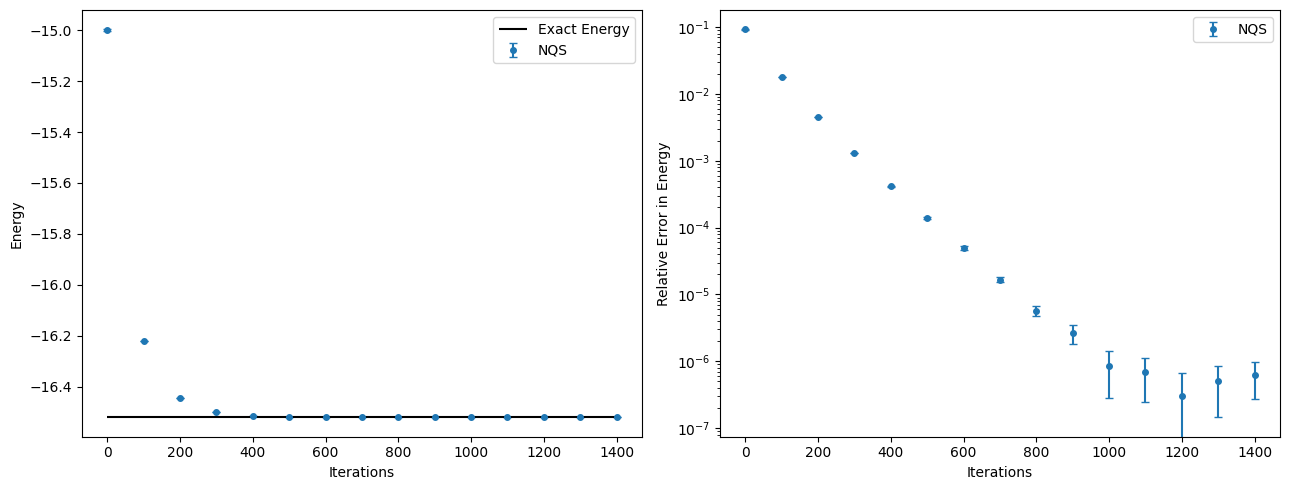

In [22]:
# Plot Energy

# Relative error and propagated standard deviation
rel_err_energy = np.abs((Energy_vs - E_gs) / E_gs)
rel_err_energy_stdev = Energy_vs_stdev / np.abs(E_gs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --------------------------------
# Energy
# --------------------------------
ax1.errorbar(
    iterations,
    Energy_vs,
    yerr=Energy_vs_stdev,
    fmt='o',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS"
)

ax1.hlines(
    E_gs,
    xmin=iterations[0],
    xmax=iterations[-1],
    color="black",
    label="Exact Energy"
)

ax1.set_xlabel("Iterations")
ax1.set_ylabel("Energy")
ax1.legend()


# --------------------------------
# Relative error
# --------------------------------
ax2.errorbar(
    iterations,
    rel_err_energy,
    yerr=rel_err_energy_stdev,
    fmt='o',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS"
)

ax2.set_yscale("log")
ax2.set_xlabel("Iterations")
ax2.set_ylabel("Relative Error in Energy")
ax2.legend()

plt.tight_layout()
plt.show()

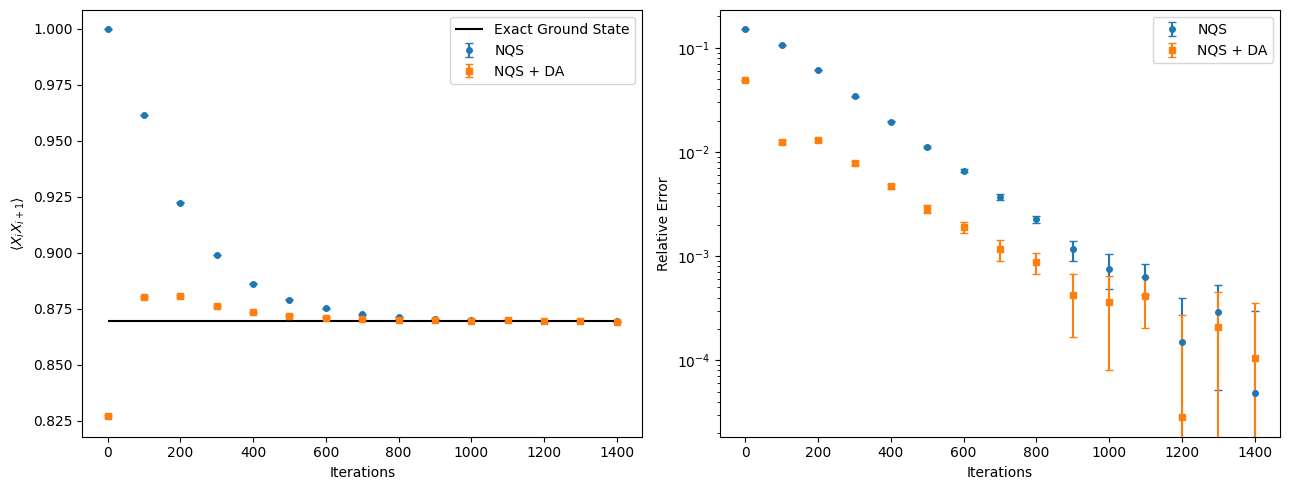

In [23]:
# Plot XX Correlation Function


# Relative errors and propagated standard deviations
rel_err_corr_x = np.abs((corr_x_vs - corr_x_gs) / corr_x_gs)
rel_err_corr_x_stdev = corr_x_vs_stdev / np.abs(corr_x_gs)

rel_err_corr_x_DA = np.abs((corr_x_vs_DA - corr_x_gs) / corr_x_gs)
rel_err_corr_x_DA_stdev = corr_x_vs_DA_stdev / np.abs(corr_x_gs)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --------------------------------
# corr_x
# --------------------------------
ax1.errorbar(
    iterations,
    corr_x_vs,
    yerr=corr_x_vs_stdev,
    fmt='o',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS"
)

ax1.errorbar(
    iterations,
    corr_x_vs_DA,
    yerr=corr_x_vs_DA_stdev,
    fmt='s',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS + DA"
)

ax1.hlines(
    corr_x_gs,
    xmin=iterations[0],
    xmax=iterations[-1],
    color="black",
    label="Exact Ground State"
)

ax1.set_xlabel("Iterations")
ax1.set_ylabel(r"$\langle X_i X_{i+1} \rangle$")
ax1.legend()


# --------------------------------
# Relative error
# --------------------------------
ax2.errorbar(
    iterations,
    rel_err_corr_x,
    yerr=rel_err_corr_x_stdev,
    fmt='o',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS"
)

ax2.errorbar(
    iterations,
    rel_err_corr_x_DA,
    yerr=rel_err_corr_x_DA_stdev,
    fmt='s',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS + DA"
)

ax2.set_yscale("log")
ax2.set_xlabel("Iterations")
ax2.set_ylabel("Relative Error")
ax2.legend()

plt.tight_layout()
plt.show()

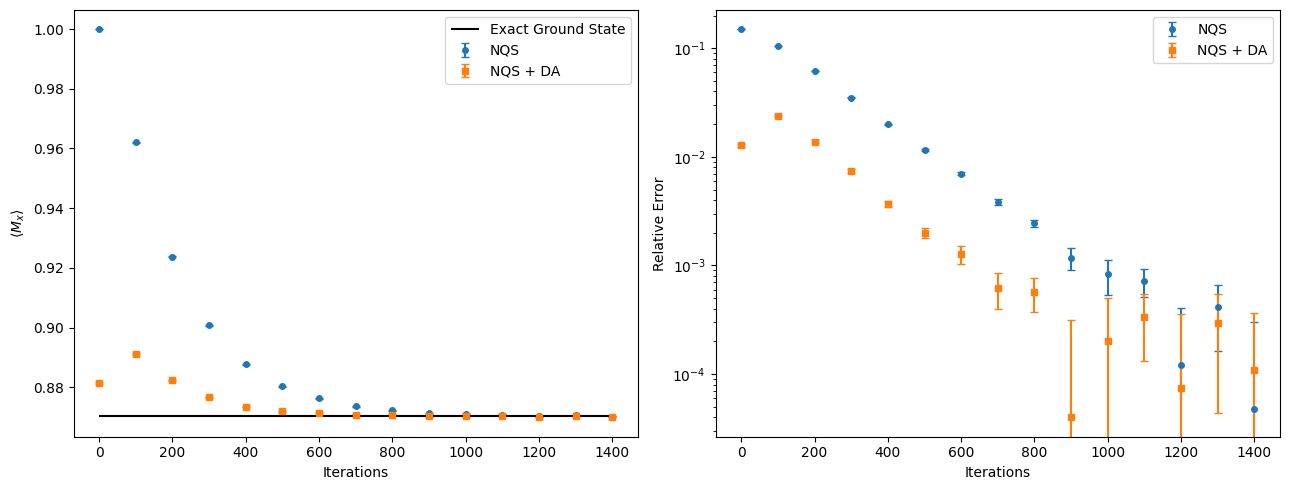

In [24]:
# Plot X Magnetization


# Relative errors and propagated standard deviations
rel_err_mag_x = np.abs((mag_x_vs - mag_x_gs) / mag_x_gs)
rel_err_mag_x_stdev = mag_x_vs_stdev / np.abs(mag_x_gs)

rel_err_mag_x_DA = np.abs((mag_x_vs_DA - mag_x_gs) / mag_x_gs)
rel_err_mag_x_DA_stdev = mag_x_vs_DA_stdev / np.abs(mag_x_gs)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --------------------------------
# Magnetization
# --------------------------------
ax1.errorbar(
    iterations,
    mag_x_vs,
    yerr=mag_x_vs_stdev,
    fmt='o',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS"
)

ax1.errorbar(
    iterations,
    mag_x_vs_DA,
    yerr=mag_x_vs_DA_stdev,
    fmt='s',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS + DA"
)

ax1.hlines(
    mag_x_gs,
    xmin=iterations[0],
    xmax=iterations[-1],
    color="black",
    label="Exact Ground State"
)

ax1.set_xlabel("Iterations")
ax1.set_ylabel(r"$\langle M_x \rangle$")
ax1.legend()


# --------------------------------
# Relative error
# --------------------------------
ax2.errorbar(
    iterations,
    rel_err_mag_x,
    yerr=rel_err_mag_x_stdev,
    fmt='o',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS"
)

ax2.errorbar(
    iterations,
    rel_err_mag_x_DA,
    yerr=rel_err_mag_x_DA_stdev,
    fmt='s',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS + DA"
)

ax2.set_yscale("log")
ax2.set_xlabel("Iterations")
ax2.set_ylabel("Relative Error")
ax2.legend()

plt.tight_layout()
plt.show()

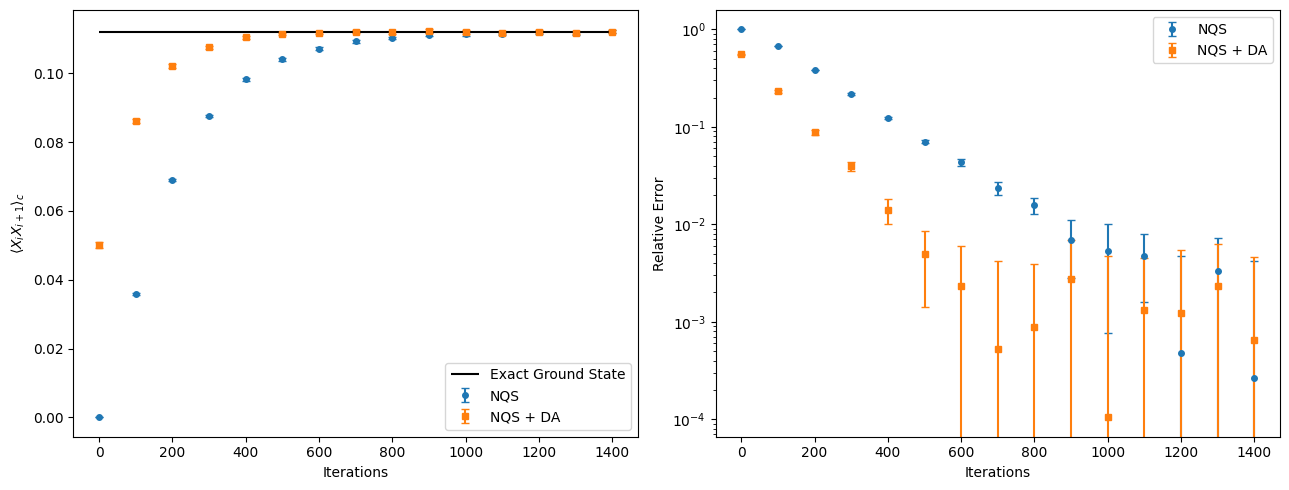

In [25]:
# Plot XX Connected Correlation Function


# Relative errors and propagated standard deviations
rel_err_conn_corr_x = np.abs((conn_corr_x_vs - conn_corr_x_gs) / conn_corr_x_gs)
rel_err_conn_corr_x_stdev = (conn_corr_x_vs_stdev / np.abs(conn_corr_x_gs))
rel_err_conn_corr_x_DA = np.abs((conn_corr_x_vs_DA - conn_corr_x_gs) / conn_corr_x_gs)
rel_err_conn_corr_x_DA_stdev = (conn_corr_x_vs_DA_stdev / np.abs(conn_corr_x_gs))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --------------------------------
# Connected correlation function
# --------------------------------
ax1.errorbar(
    iterations,
    conn_corr_x_vs,
    yerr=conn_corr_x_vs_stdev,
    fmt='o',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS"
)

ax1.errorbar(
    iterations,
    conn_corr_x_vs_DA,
    yerr=conn_corr_x_vs_DA_stdev,
    fmt='s',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS + DA"
)

ax1.hlines(
    conn_corr_x_gs,
    xmin=iterations[0],
    xmax=iterations[-1],
    color="black",
    label="Exact Ground State"
)

ax1.set_xlabel("Iterations")
ax1.set_ylabel(r"$\langle X_i X_{i+1}\rangle_c$")
#ax1.set_ylim([.1, .12])
ax1.legend()


# --------------------------------
# Relative error
# --------------------------------
ax2.errorbar(
    iterations,
    rel_err_conn_corr_x,
    yerr=rel_err_conn_corr_x_stdev,
    fmt='o',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS"
)

ax2.errorbar(
    iterations,
    rel_err_conn_corr_x_DA,
    yerr=rel_err_conn_corr_x_DA_stdev,
    fmt='s',
    linestyle='none',
    capsize=3,
    markersize=4,
    label="NQS + DA"
)


ax2.set_yscale("log")
ax2.set_xlabel("Iterations")
ax2.set_ylabel("Relative Error")
ax2.legend()

plt.tight_layout()
plt.show()